# Tensile-test analysis as an ontology-portable workflow

Ten tensile tests on S355 steel are described with RDF in three contributions (parallel, perpendicular and diagonal to the rolling direction). This notebook analyses their raw stress–strain curves with a `pyiron_workflow` workflow and shows how semantic concepts let the *description* of the data and the *analysis* of the data stay separate.

| Section | What we will do |
| --- | --- |
| 1. Description vs analysis | Why the ontology stops at a boundary |
| 2. Inputs | Choose the ontology profile and the graph source |
| 3. Exploration | Check conformance and list the specimens (ontology-aware) |
| 4. Acquisition | Turn graph content into neutral records (the boundary) |
| 5. Analysis | Run the batch workflow (ontology-agnostic) |
| 6. Results | Properties, group statistics, comparison with lab values, uncertainty, figure |
| 7. Switching the ontology | Run the same workflow on PMDco3/TTO data |
| 8. The workflow as a knowledge graph | Export, query and validate the workflow with semantikon |
| 9. Limitations and open points | What the results may and may not claim |

All properties are **method-defined, ISO 6892-1-inspired**. The notebook makes no claim of conformity with ISO 6892-1 or its Annex G.

## 1. Description vs analysis

The research graphs say *what* was measured: which specimen was tested, its cross-section and gauge length, which CSV file holds its curve, which column is the force and in which unit. They say this with the concepts of an ontology. The analysis needs none of these concepts; it needs numbers and arrays in known units.

The workflow therefore has a boundary:

- **Exploration** (conformance check, specimen listing) and **acquisition** (specimen metadata, curve location and column semantics, lab-reported values) are the only steps that know an ontology. An *ontology profile* holds everything ontology-specific: SPARQL queries, the unit vocabulary and naming conventions.
- Acquisition delivers **neutral records**: plain numbers, arrays and units, with no IRIs.
- **Analysis** steps are ontology-agnostic. They never see an IRI or a SPARQL query; their inputs and outputs carry only units and generic QUDT quantity kinds.

```
graph (pmdco2 or pmdco3) --exploration--> specimen IDs
                         --acquisition--> neutral records --analysis--> properties, flags, uncertainty
```

Consequences, shown in this notebook:

- Switching the ontology means changing the profile ID and the source, plus the optional curve locator if the new graph does not link its raw curves. The analysis code and, for identical raw curves, its results stay the same (section 7).
- The workflow itself can be described as a knowledge graph, and queried for which steps know an ontology and which units the results carry (section 8).
- The analysis code lives in the importable package `tensile_workflow` next to this notebook; the notebook only calls it.

### Setup

Start Jupyter in `pmd_public-infrastructure-demonstrator/notebooks` and select the `pmd-demonstrator` kernel. The setup checks this location and then makes the demonstrator directory the working directory: local Turtle locations in the source are given relative to it, so that the knowledge graphs of a run contain no machine-specific paths. It also puts the demonstrator directory on `sys.path` to import `tensile_workflow`.

*Execution class: read-only (local).*

In [1]:
import dataclasses
import os
import sys
import tempfile
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Safe to re-run: afterwards the working directory is the demonstrator directory.
demo_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (demo_dir / "tensile_workflow").is_dir() or not (demo_dir / "notebooks").is_dir():
    raise RuntimeError("Start the kernel in pmd_public-infrastructure-demonstrator/notebooks.")
os.chdir(demo_dir)
if str(demo_dir) not in sys.path:
    sys.path.insert(0, str(demo_dir))

from tensile_workflow import acquisition, analysis, exploration, sources, workflows
from tensile_workflow import knowledge_graph as kg
from tensile_workflow.profiles import available_profiles, pmdco3_tto

# semantikon's provenance hashing triggers an upstream networkx notice about changed hashes.
warnings.filterwarnings("ignore", message="The hashes produced for directed graphs", category=UserWarning)
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", None)  # pandas would otherwise cut IRIs, URLs and hashes.

## 2. Inputs: ontology profile and source

The workflow has two essential inputs. Both are JSON-able, so they appear as plain values in the knowledge graph of a run.

- `ontology_profile`: the ID of a registered profile. `pmdco2-tto` describes the demonstrator's graphs (PMDco 2 with the Tensile Test Ontology); `pmdco3-tto` describes the PMDco3/TTO version of the same tests (section 7).
- `source`: where the graphs are. By default the three Ontodocker datasets of the public demonstrator. The commented alternative uses the local Turtle copies in `datasets/`, with paths relative to the demonstrator directory; the raw curves are still downloaded from the data host.
- `curve_locator`: only for profiles whose graph does not link the raw curves. `None` means the curve locations and column semantics come from the graph.
- `run_pmdco3_comparison`: run section 7.
- `kg_output_dir`: a directory **outside the repository** for the saved knowledge graphs; a leading `~` is expanded, and existing graph files there are not overwritten. `None` uses a temporary directory.

The next cell is tagged `parameters` for papermill, e.g. `papermill tensile-test-workflow.ipynb /tmp/tensile-test-workflow.ipynb -p run_pmdco3_comparison False`. Pass a dictionary such as `source` with `-y`.

In [2]:
ontology_profile = "pmdco2-tto"
source = {
    "kind": "ontodocker",
    "datasets": [
        "pmdco2_tto_example_parallel",
        "pmdco2_tto_example_perpendicular",
        "pmdco2_tto_example_diagonal",
    ],
}
# Alternative without Ontodocker: the local Turtle copies, relative to the demonstrator directory.
# source = {
#     "kind": "turtle",
#     "locations": [
#         "datasets/pmdco2_tto_example_parallel.ttl",
#         "datasets/pmdco2_tto_example_perpendicular.ttl",
#         "datasets/pmdco2_tto_example_diagonal.ttl",
#     ],
# }
curve_locator = None  # Only for profiles whose graph does not link the raw curves.
run_pmdco3_comparison = True  # Section 7: reads the pinned PMDco3/TTO graph and curves from GitHub.
kg_output_dir = None  # Outside the repository; None uses a temporary directory.

### Check the inputs and credentials

An Ontodocker source needs `ONTODOCKER_ADDRESS`, and `ONTODOCKER_TOKEN` if the service requires it. Set them in the environment before starting Jupyter. The package reads them only inside its Ontodocker access path; they are never workflow inputs or outputs, so they cannot enter run data or knowledge graphs. This cell prints neither. A source with keys other than the documented ones is rejected.

*Execution class: read-only (local).*

In [3]:
if ontology_profile not in available_profiles():
    raise ValueError(f"Unknown ontology profile {ontology_profile!r}; available: {available_profiles()}")
source_kind, source_parts = sources.validate_source(source)
if source_kind == "ontodocker" and not os.getenv("ONTODOCKER_ADDRESS", "").strip():
    raise RuntimeError("Set ONTODOCKER_ADDRESS (and ONTODOCKER_TOKEN if required) before starting Jupyter.")

print("Ontology profile:", ontology_profile)
print(f"Source ({source_kind}):", ", ".join(source_parts))

Ontology profile: pmdco2-tto
Source (ontodocker): pmdco2_tto_example_parallel, pmdco2_tto_example_perpendicular, pmdco2_tto_example_diagonal


## 3. Exploration (ontology-aware)

The first workflow stage checks that every part of the source conforms to the profile, using the profile's SPARQL ASK queries, and fails early on a mismatch. Only then does it list the specimens. The table below shows each ASK per part; the specimen table includes the IRI of each test, because this stage is allowed to know the graph.

*Execution class: network-read (SPARQL queries to Ontodocker); read-only for a local Turtle source.*

In [4]:
display(pd.DataFrame(exploration.conformance_results(ontology_profile, source)))

exploration_run = workflows.build_exploration_workflow().run(profile_id=ontology_profile, source=source)
specimen_ids = list(exploration_run.outputs.specimen_ids)
display(exploration.specimen_table(ontology_profile, source))

,tensile test with test-piece name,cross-section area with value and unit,orientation (MaterialRelated),CSVW curve table with column schema
pmdco2_tto_example_parallel,True,True,True,True
pmdco2_tto_example_perpendicular,True,True,True,True
pmdco2_tto_example_diagonal,True,True,True,True


,specimen_id,orientation,process
0,Zd2,diagonal to rolling direction,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-9_process
1,Zd3,diagonal to rolling direction,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process
2,Zx1,in rolling direction,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-1_process
3,Zx2,in rolling direction,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-2_process
4,Zx3,in rolling direction,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-3_process
5,Zx4,in rolling direction,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-4_process
6,Zy1,perpendicular to rolling direction,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-5_process
7,Zy2,perpendicular to rolling direction,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-6_process
8,Zy3,perpendicular to rolling direction,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-7_process
9,Zy4,perpendicular to rolling direction,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-8_process


## 4. Acquisition into neutral records (the boundary)

Acquisition turns the graph content of one specimen into the neutral data contract, in fixed units (N, mm, mm², strain as a ratio, MPa, GPa, %):

- a specimen record: S0, the individual cross-section measurements s1–s3, L0, Lu, Su, orientation, lab notes, the curve location and column semantics;
- the raw curve, downloaded into memory with a token-free client, and its SHA-256;
- the lab-reported values, used only for the comparison in section 6, never as analysis inputs.

Every unit is converted through an explicit table; an unknown or mismatched unit raises an error. The record keeps one opaque provenance string (the test's IRI) for reporting only. Small adapter steps then unpack the record and the curve into the annotated arrays and scalars below. **This is everything the analysis receives**: no IRIs, no SPARQL.

*Execution class: network-read (SPARQL queries; download of one curve CSV from the data host).*

In [5]:
example_id = specimen_ids[0]
record = acquisition.build_specimen_record(ontology_profile, source, example_id, curve_locator)
curve = acquisition.download_curve(record)
reported = acquisition.build_reported_properties(ontology_profile, source, example_id)

s0_mm2, measurements_mm2, l0_mm, lu_mm, su_mm2, rate_switch_strain = workflows.specimen_geometry(record)
time_s, crosshead_mm, force_n, strain, curve_sha256, curve_url = workflows.curve_channels(curve)

geometry = {
    "S0 / mm²": s0_mm2,
    "s1..sn / mm²": measurements_mm2,
    "L0 / mm": l0_mm,
    "Lu / mm": lu_mm,
    "Su / mm²": su_mm2,
    "rate-switch strain / 1 (diagnostic only)": rate_switch_strain,
    "curve SHA-256": curve_sha256,
}
display(pd.Series(geometry, name=example_id).to_frame())
channels = pd.DataFrame(
    {"time / s": time_s, "crosshead / mm": crosshead_mm, "force / N": force_n, "strain / 1": strain}
)
display(channels.describe().loc[["count", "min", "max"]])
display(pd.Series(dataclasses.asdict(reported), name="lab-reported (comparison only)").to_frame())

,Zd2
S0 / mm²,120.715
s1..sn / mm²,"[120.649, 120.683, 120.813]"
L0 / mm,60.0
Lu / mm,80.02
Su / mm²,48.813
rate-switch strain / 1 (diagnostic only),0.04
curve SHA-256,7efcde377ef0b1914b7b32b65650271f523a0107ce2657d586ba90ecc0fe22dd


,time / s,crosshead / mm,force / N,strain / 1
count,12332.000,12332.0000,12332.00,2021.000
min,0.000,-0.0004,279.44,0.001
max,1217.812,28.0066,62124.42,0.042


,lab-reported (comparison only)
specimen_id,Zd2
e_gpa,201.0
rp02_mpa,390.0
reh_mpa,399.0
rel_mpa,None
rm_mpa,515.0
fm_n,62168.0
a_percent,33.5
z_percent,60.0


## 5. Analysis (ontology-agnostic)

The second stage is one flat per-specimen workflow per specimen (acquisition, adapters, analysis steps, comparison), followed by aggregation steps for the results table, the per-orientation summary and the comparison table. It is assembled programmatically rather than with a loop because semantikon cannot yet export workflows with flow controllers ([pyiron/semantikon#541](https://github.com/pyiron/semantikon/issues/541)).

The method in brief (method specification v2.6; parameters are fixed method defaults):

- **Raw samples.** No smoothing is applied in any property extraction.
- **Extensometer validity.** The record is split into windows of 0.1 mm crosshead travel. The extensometer counts as removed from the first window after which, until the end, strain no longer follows the crosshead (ratio below 0.05), or is missing, zero or jumps. Properties that need strain are evaluated only before that point; otherwise they are NaN with the flag `extensometer_invalid`. A strain channel that vendor software continues from the crosshead cannot be detected.
- **Yield type, ReH and ReL.** A drop below the running maximum by more than max(0.5 %, 5 × noise) above half of Rm, followed by plastic flow, marks discontinuous yielding. The noise level is the residual scatter of the provisional fit, so it also picks up anything else that bends the curve in that window. ReH is the maximum stress before the first decrease; ReL is the lowest stress during yielding, ignoring the initial transient (`ReL_incl_transient` is also kept). Otherwise yielding is continuous, and ReH and ReL are NaN with a flag.
- **E window.** E is the least-squares slope in the stress window 10–40 % of ReH (discontinuous) or of Rp0.2 (continuous), found after a provisional fit that fixes the noise level. It is reported as *E: regression slope of the elastic part (mE-type), not Annex-G-conformant*, not as a material modulus.
- **Rp0.2** is the first crossing of 0.2 % plastic strain, flagged `in_yield_plateau` when a discontinuous curve crosses during its yield range.
- **Fm and Rm** use the force maximum after work hardening begins.
- **Ag band.** Ag and Agt are read at the strain mid-point of the band of samples near the force maximum, whose half-width is reported. They need the whole band before the extensometer end.
- **A and Z** come from the graph metadata (L0, Lu, S0, Su).

An error in one specimen's branch, such as a failed download, aborts the whole batch run; there are no partial results. To run a subset, pass the IDs that work: `workflows.run_tensile_analysis(ontology_profile, source, curve_locator, specimen_ids=[...])`.

*Execution class: network-read. The run repeats exploration and acquisition for every specimen: SPARQL queries and one curve download per specimen.*

In [6]:
print(analysis.METHOD_LABEL)
print(analysis.E_LABEL)

tensile = workflows.run_tensile_analysis(ontology_profile, source, curve_locator)
print(f"Batch run {tensile.batch_run.status}: {len(tensile.specimen_ids)} specimens ({', '.join(tensile.specimen_ids)})")

method-defined, ISO 6892-1-inspired
E: regression slope of the elastic part (mE-type), not Annex-G-conformant


Batch run finished: 10 specimens (Zd2, Zd3, Zx1, Zx2, Zx3, Zx4, Zy1, Zy2, Zy3, Zy4)


## 6. Results

### Per-specimen properties

Undefined values are NaN, and the flags name the rule that produced them. Two entries need care. Ag and Agt are NaN on all ten specimens, because the strain record ends long before the force maximum (section 9). Zy3 is listed as continuous with ReH and ReL NaN although its curve has a clear upper yield peak (407.6 MPa; in the figure below it overlaps the peak of Zy4). This is a failure of the method, not a property of the specimen, and the flag `reh:extensometer_invalid` does not name the real cause (section 9). The flags and lab notes are shown in full next to each specimen; no specimen is excluded. `fm:no_return_to_reh` marks a result whose stress never returns to ReH, which is unreliable for a record with a gradual force decline at its end (section 9). The line below the tables names any such specimen.

The second table holds the diagnostics behind these values: `rel_incl_transient_mpa` (`ReL_incl_transient`, the lowest stress including the initial transient), `reh_sample_increment_mpa` (the sampling resolution at the ReH peak, since a sampled peak reads low), the E fit (`e_n` points in the stress window `e_window_mpa`, with `e_r2`), the strain origin `strain_origin`, and `dropped_samples`, the number of non-finite samples per channel.

*Execution class: read-only (local).*

In [7]:
results = tensile.results.set_index("specimen_id")
property_columns = ["orientation", "yield_type", "e_gpa", "reh_mpa", "rel_mpa", "rp02_mpa", "fm_n", "rm_mpa",
                    "ag_percent", "agt_percent", "a_percent", "z_percent"]
display(results[property_columns])
diagnostic_columns = ["rel_incl_transient_mpa", "reh_sample_increment_mpa", "e_n", "e_window_mpa", "e_r2",
                      "strain_origin", "dropped_samples"]
display(results[diagnostic_columns])
with pd.option_context("display.max_colwidth", None):  # pandas would otherwise cut long flag lists.
    display(results[["notes", "flags"]])
no_return = results.index[results["flags"].str.contains("fm:no_return_to_reh")]
print("Stress never returns to ReH (fm:no_return_to_reh):", ", ".join(no_return) or "no specimen")

,orientation,yield_type,e_gpa,reh_mpa,rel_mpa,rp02_mpa,fm_n,rm_mpa,ag_percent,agt_percent,a_percent,z_percent
specimen_id,,,,,,,,,,,,
Zd2,diagonal to rolling direction,discontinuous,200.9203,399.3685,395.4093,389.6655,62124.42,514.6371,NaN,NaN,33.3667,59.5634
Zd3,diagonal to rolling direction,discontinuous,158.6705,396.2100,389.7225,395.4470,61734.63,511.4420,NaN,NaN,33.2833,63.6111
Zx1,in rolling direction,discontinuous,194.3460,379.9224,373.0554,375.4920,61993.74,513.8909,NaN,NaN,NaN,56.3489
Zx2,in rolling direction,discontinuous,198.8678,378.8463,374.2157,373.5275,60666.44,503.6900,NaN,NaN,35.0000,58.8315
Zx3,in rolling direction,discontinuous,200.0756,379.4088,370.7641,375.8609,60627.81,503.5700,NaN,NaN,35.1667,58.0534
Zx4,in rolling direction,discontinuous,195.7558,388.6658,382.8679,381.9096,62252.80,518.7128,NaN,NaN,34.8333,60.5196
Zy1,perpendicular to rolling direction,discontinuous,209.8907,399.5549,393.7093,396.1765,61332.51,508.2285,NaN,NaN,NaN,53.5636
Zy2,perpendicular to rolling direction,discontinuous,213.8779,398.7837,392.7918,389.9908,61165.14,506.7115,NaN,NaN,35.0000,55.7327
Zy3,perpendicular to rolling direction,continuous,205.0917,NaN,NaN,395.7685,60930.20,504.9618,NaN,NaN,33.5667,58.2598


,rel_incl_transient_mpa,reh_sample_increment_mpa,e_n,e_window_mpa,e_r2,strain_origin,dropped_samples
specimen_id,,,,,,,
Zd2,395.4093,0.0450,135,"(39.93685126123514, 159.74740504494056)",1.0000,9.5733e-04,"{'force': 0, 'strain': 10311, 'crosshead': 0}"
Zd3,389.7225,0.1437,138,"(39.62099961062739, 158.48399844250957)",0.9954,9.0402e-05,"{'force': 0, 'strain': 10226, 'crosshead': 0}"
Zx1,373.0554,0.2398,130,"(37.99224112205312, 151.9689644882125)",1.0000,5.8259e-04,"{'force': 0, 'strain': 541, 'crosshead': 0}"
Zx2,374.2157,0.0354,131,"(37.884626880541994, 151.53850752216798)",1.0000,-7.0105e-04,"{'force': 0, 'strain': 10861, 'crosshead': 0}"
Zx3,370.7641,0.0150,132,"(37.94087843449948, 151.76351373799793)",1.0000,-2.2596e-04,"{'force': 0, 'strain': 11228, 'crosshead': 0}"
Zx4,382.8679,0.1810,134,"(38.86658223207292, 155.4663289282917)",1.0000,-8.2102e-05,"{'force': 0, 'strain': 10719, 'crosshead': 0}"
Zy1,393.7093,0.0202,138,"(39.95549349928322, 159.8219739971329)",1.0000,-6.3581e-04,"{'force': 0, 'strain': 9825, 'crosshead': 0}"
Zy2,392.7918,0.1306,137,"(39.87836964625963, 159.5134785850385)",1.0000,9.2766e-04,"{'force': 0, 'strain': 10652, 'crosshead': 0}"
Zy3,NaN,NaN,136,"(39.57685112657873, 158.30740450631492)",1.0000,-3.6954e-04,"{'force': 0, 'strain': 10124, 'crosshead': 0}"


,notes,flags
specimen_id,,
Zd2,"Proben aus Stahlblech entnommen, diagonal der Walzrichtung",extensometer:extensometer_ended_early; extensometer:near_rate_switch; ag:extensometer_invalid; agt:extensometer_invalid
Zd3,"Proben aus Stahlblech entnommen, diagonal der Walzrichtung",extensometer:extensometer_ended_early; extensometer:near_rate_switch; ag:extensometer_invalid; agt:extensometer_invalid
Zx1,In Walzrichtung aus Stahlblech entnommen; Abweichend von den anderen Proben. Weggeschwindigkeit wurde erhöht.,ag:extensometer_invalid; agt:extensometer_invalid; a:missing_input
Zx2,"In Walzrichtung aus Stahlblech entnommen; Extensometer nach 3,9 % Dehnung der Proben entfernt. Keine Erhöhung der Geschwindigkeit.",extensometer:extensometer_ended_early; extensometer:near_rate_switch; ag:extensometer_invalid; agt:extensometer_invalid
Zx3,"In Walzrichtung aus Stahlblech entnommen; Extensometer nach 3,9 % Dehnung der Proben entfernt. Keine Erhöhung der Geschwindigkeit.",extensometer:extensometer_ended_early; extensometer:near_rate_switch; ag:extensometer_invalid; agt:extensometer_invalid
Zx4,"In Walzrichtung aus Stahlblech entnommen; Extensometer nach 3,9 % Dehnung der Proben entfernt. Keine Erhöhung der Geschwindigkeit.",extensometer:extensometer_ended_early; extensometer:near_rate_switch; ag:extensometer_invalid; agt:extensometer_invalid
Zy1,"Proben aus Stahlblech entnommen, entgegen der Walzrichtung",extensometer:near_rate_switch; ag:extensometer_invalid; agt:extensometer_invalid; a:missing_input
Zy2,"Proben aus Stahlblech entnommen, entgegen der Walzrichtung",extensometer:extensometer_ended_early; extensometer:near_rate_switch; ag:extensometer_invalid; agt:extensometer_invalid
Zy3,"Proben aus Stahlblech entnommen, entgegen der Walzrichtung",extensometer:extensometer_ended_early; extensometer:near_rate_switch; reh:extensometer_invalid; reh:no_upper_yield; rel:no_upper_yield; ag:extensometer_invalid; agt:extensometer_invalid


Stress never returns to ReH (fm:no_return_to_reh): no specimen


### Per-orientation summary

Descriptive statistics only: n is 2–4 per orientation, so no hypothesis tests and no claims about orientation effects. `n` counts the specimens with a defined value; `sd` uses ddof = 1. Zx1 was tested at a different speed (lab note).

The diagonal group has two specimens, and Zd3's E is the slope of a segment that is not straight (see the comparison below). Its E mean (179.8 GPa) and sd (29.9 GPa) therefore reflect that one record; they do not estimate the modulus in this orientation or its scatter. In the perpendicular group, ReH and ReL have n = 3 because Zy3 has no value, and the Rp0.2 statistics include Zy3's value, which is a plateau stress (section 9). Ag and Agt have n = 0 in every group.

*Execution class: read-only (local).*

In [8]:
summary = tensile.orientation_summary
display(
    summary.pivot(index="quantity", columns=workflows.GROUP_COLUMN, values=["n", "mean", "sd"])
    .reindex(list(workflows.SUMMARY_QUANTITIES))
)

n                       \
orientation diagonal to rolling direction in rolling direction   
quantity                                                         
e_gpa                                 2.0                  4.0   
reh_mpa                               2.0                  4.0   
rel_mpa                               2.0                  4.0   
rp02_mpa                              2.0                  4.0   
fm_n                                  2.0                  4.0   
rm_mpa                                2.0                  4.0   
ag_percent                            0.0                  0.0   
agt_percent                           0.0                  0.0   
a_percent                             2.0                  3.0   
z_percent                             2.0                  4.0   

                                                                        mean  \
orientation perpendicular to rolling direction diagonal to rolling direction   
quantity                                                                       
e_gpa                                      4.0                      179.7954   
reh_mpa                                    3.0                      397.7893   
rel_mpa                                    3.0                      392.5659   
rp02_mpa                                   4.0                      392.5562   
fm_n                                       4.0                    61929.5250   
rm_mpa                                     4.0                      513.0396   
ag_percent                                 0.0                           NaN   
agt_percent                                0.0                           NaN   
a_percent                                  3.0                       33.3250   
z_percent                                  4.0                       61.5872   

                                                                     \
orientation in rolling direction perpendicular to rolling direction   
quantity                                                              
e_gpa                   197.2613                           209.9685   
reh_mpa                 381.7108                           401.8635   
rel_mpa                 375.2258                           395.1709   
rp02_mpa                376.6975                           395.9185   
fm_n                  61385.1975                         61352.7975   
rm_mpa                  509.9659                           508.4831   
ag_percent                   NaN                                NaN   
agt_percent                  NaN                                NaN   
a_percent                35.0000                            33.8222   
z_percent                58.4383                            55.6661   

                                       sd                       \
orientation diagonal to rolling direction in rolling direction   
quantity                                                         
e_gpa                             29.8752               2.6625   
reh_mpa                            2.2334               4.6574   
rel_mpa                            4.0212               5.2927   
rp02_mpa                           4.0882               3.6225   
fm_n                             275.6232             858.9347   
rm_mpa                             2.2593               7.5765   
ag_percent                            NaN                  NaN   
agt_percent                           NaN                  NaN   
a_percent                          0.0589               0.1667   
z_percent                          2.8621               1.7321   

                                                
orientation perpendicular to rolling direction  
quantity                                        
e_gpa                                   3.6590  
reh_mpa                                 4.6823  
rel_mpa                                 3.3577  
rp02_mpa                                4.7991  
fm_n          

### Comparison with lab-reported values

Each computed value is compared with the value the lab reported in the graph, against tolerances fixed before any real data were analysed: Fm ±0.1 %, Rm ±(0.1 % + 0.5 MPa), ReH and Rp0.2 ±2 %, E ±10 % (barely discriminating), A and Z rounding-aware. ReL is not compared because no lab values exist. The outcome is `within`, `outside`, or `not_comparable` when either value is missing.

This is a **consistency check with the lab's software, not a validation**. The lab values are not ground truth; their evaluation windows are unknown. An `outside` result is reported, never tuned away. Candidate explanations to distinguish are the evaluation-window choice, baseline and seating effects, extensometer slip or removal, and differences in the lab software.

`within` only says that two evaluations of the same raw curve with the same S0 agree inside the tolerance; errors they share cannot show up. Fm and Rm depend on little more than the maximum of the force channel, and A and Z are arithmetic on the graph's metadata. The ReH tolerance is about as wide as the yield drop: eight of the nine ReL values found here would also be `within` if compared with the lab's ReH. The close agreement in E on nine specimens (about 0.54 % at most, on values the lab rounds to 1 GPa) shows that both fits find the same slope, not that the slope is the material's modulus.

`not_comparable` is not agreement. For the ReH of Zy3 see section 9; for the Rp0.2 of Zd3 and Zy3 the lab gives no value.

**Zd3, E `outside`.** The computed 158.7 GPa (lab 195 GPa, −18.6 %) is reported as the method gives it, but it should not be read as a modulus: the curve is not straight in the fit window. This shows in R² = 0.9954 (all others print as 1.0000), `e_linearity_rel_diff` = −0.14, a window range of 152–180 GPa that does not contain the lab value, and `e_n_eff` = 1.4, which leaves the standard error of 0.92 GPa without meaning. No flag marks this, because the method has no rule for it. A local check of the raw curve, outside the method, gives slopes of 192–201 GPa below 70 MPa, 136 GPa at 100–130 MPa and 188 GPa at 160–200 MPa; a modulus does not vary like that within one loading. The gap to the lab value corresponds to about 7 µm of extra extensometer movement on the 50 mm extensometer gauge length, less than 1 % of the crosshead travel in the window, so the crosshead cannot show the cause. Settling or slip of the extensometer or grips, bending and local deformation all remain possible. How the lab obtained 195 GPa is also unknown. The lab's evaluation report, a second strain channel or a repeat test could decide this.

The last table below shows the computed value, the lab value and the deviation in percent for every specimen and quantity.

*Execution class: read-only (local).*

In [9]:
comparison = tensile.comparison
display(pd.crosstab(comparison["quantity"], comparison["outcome"]))
display(comparison[comparison["outcome"] != "within"])

# Rounded, because one tiny deviation would switch its whole column to scientific notation; + 0.0 removes -0.0.
deviation_percent = (100 * comparison["rel_deviation"]).round(4) + 0.0
values = ["computed", "lab", "deviation / %"]
against_lab = comparison.assign(**{"lab": comparison["reported"], "deviation / %": deviation_percent}).pivot(
    index="quantity", columns="specimen_id", values=values
)
display(against_lab.stack(level=0).reindex(pd.MultiIndex.from_product([comparison["quantity"].unique(), values])))

outcome,not_comparable,outside,within
quantity,,,
a_percent,2,0,8
e_gpa,0,1,9
fm_n,0,0,10
reh_mpa,1,0,9
rm_mpa,0,0,10
rp02_mpa,2,0,8
z_percent,0,0,10


,specimen_id,orientation,quantity,computed,reported,rel_deviation,outcome,tolerance
10,Zd3,diagonal to rolling direction,rp02_mpa,395.4470,NaN,NaN,not_comparable,±2 %
11,Zd3,diagonal to rolling direction,e_gpa,158.6705,195.0,-0.1863,outside,±10 %
19,Zx1,in rolling direction,a_percent,NaN,NaN,NaN,not_comparable,rounding-aware: rounds to the lab integer (±0.5 pp at a tie)
47,Zy1,perpendicular to rolling direction,a_percent,NaN,NaN,NaN,not_comparable,rounding-aware: rounds to the lab integer (±0.5 pp at a tie)
58,Zy3,perpendicular to rolling direction,reh_mpa,NaN,408.0,NaN,not_comparable,±2 %
59,Zy3,perpendicular to rolling direction,rp02_mpa,395.7685,NaN,NaN,not_comparable,±2 %


specimen_id                     Zd2         Zd3         Zx1         Zx2  \
fm_n      computed       62124.4200  61734.6300  61993.7400  60666.4400   
          lab            62168.0000  61681.0000  62007.0000  60704.0000   
          deviation / %     -0.0701      0.0869     -0.0214     -0.0619   
rm_mpa    computed         514.6371    511.4420    513.8909    503.6900   
          lab              515.0000    511.0000    514.0000    504.0000   
          deviation / %     -0.0705      0.0865     -0.0212     -0.0615   
reh_mpa   computed         399.3685    396.2100    379.9224    378.8463   
          lab              399.0000    396.0000    380.0000    379.0000   
          deviation / %      0.0924      0.0530     -0.0204     -0.0406   
rp02_mpa  computed         389.6655    395.4470    375.4920    373.5275   
          lab              390.0000         NaN    375.0000    374.0000   
          deviation / %     -0.0858         NaN      0.1312     -0.1263   
e_gpa     computed         200.9203    158.6705    194.3460    198.8678   
          lab              201.0000    195.0000    194.0000    199.0000   
          deviation / %     -0.0396    -18.6305      0.1783     -0.0664   
a_percent computed          33.3667     33.2833         NaN     35.0000   
          lab               33.5000     33.0000         NaN     35.0000   
          deviation / %     -0.3980      0.8586         NaN      0.0000   
z_percent computed          59.5634     63.6111     56.3489     58.8315   
          lab               60.0000     64.0000     56.0000     59.0000   
          deviation / %     -0.7276     -0.6077      0.6229     -0.2856   

specimen_id                     Zx3         Zx4         Zy1         Zy2  \
fm_n      computed       60627.8100  62252.8000  61332.5100  61165.1400   
          lab            60680.0000  62288.0000  61305.0000  61200.0000   
          deviation / %     -0.0860     -0.0565      0.0449     -0.0570   
rm_mpa    computed         503.5700    518.7128    508.2285    506.7115   
          lab              504.0000    519.0000    508.0000    507.0000   
          deviation / %     -0.0853     -0.0553      0.0450     -0.0569   
reh_mpa   computed         379.4088    388.6658    399.5549    398.7837   
          lab              379.0000    388.0000    399.0000    399.0000   
          deviation / %      0.1079      0.1716      0.1391     -0.0542   
rp02_mpa  computed         375.8609    381.9096    396.1765    389.9908   
          lab              376.0000    382.0000    396.0000    390.0000   
          deviation / %     -0.0370     -0.0237      0.0446     -0.0023   
e_gpa     computed         200.0756    195.7558    209.8907    213.8779   
          lab              199.0000    196.0000    210.0000    214.0000   
          deviation / %      0.5405     -0.1246     -0.0520     -0.0570   
a_percent computed          35.1667     34.8333         NaN     35.0000   
          lab               35.0000     35.0000         NaN     35.0000   
          deviation / %      0.4762     -0.4762         NaN      0.0000   
z_percent computed          58.0534     60.5196     53.5636     55.7327   
          lab               58.0000     61.0000     54.0000     56.0000   
          deviation / %      0.0921     -0.7875     -0.8082     -0.4772   

specimen_id                     Zy3         Zy4  
fm_n      computed       60930.2000  61983.3400  
          lab            60935.0000  61980.0000  
          deviation / %     -0.0079      0.0054  
rm_mpa    computed         504.9618    514.0305  
          lab              505.0000    514.0000  
          deviation / %     -0.0076      0.0059  
reh_mpa   computed              NaN    407.2518  
          lab              408.0000    407.0000  
          deviation / %         NaN      0.0619  
rp02_mpa  computed         395.7685    401.7382  
          lab                   NaN    402.0000  
          deviation / %         NaN     -0.0651  
e_gpa     computed         205.0917    211.0136 

### Uncertainty components

The components are reported separately and never combined:

- **S0 scatter** `s0_u_rel`: the relative standard uncertainty of the mean of the cross-section measurements s1–s3 (ν = 2). It applies equally to every stress-based value, including E; strains are unaffected. Expected magnitude: 2–8·10⁻⁴; on these tests 1.7–7.7·10⁻⁴. This is one to two orders of magnitude smaller than plausible force-class and E effects. The lab value uses the same S0, so this component cannot explain a difference from it.
- **E-window sensitivity**: the range of E, Rp0.2, Ag and Agt over a predeclared grid of windows (lower bound 5, 10 or 15 %, upper bound 30, 40 or 50 % of the reference stress). It describes sensitivity only and never selects a window. `e_linearity_rel_diff` is the relative difference of E between the windows 5–25 % and 25–50 %. The ranges are not confidence intervals. On Zy3, for example, the low end of 175 GPa comes from windows that contain the low-load event described in section 9.
- **Ag location** `ag_location_halfwidth_percent`: the half-width in strain of the near-maximum band, in percentage points. It shows how ill-conditioned Ag is near a flat maximum. All Ag and Agt columns are NaN on these tests (section 9).
- **E standard error** `e_stderr_gpa`: the OLS standard error, conditional on the window and on independent residuals; not an uncertainty. It is reported with the lag-1 residual autocorrelation `e_lag1_rho` and `e_n_eff` = n(1 − ρ)/(1 + ρ).

*Execution class: read-only (local).*

In [10]:
uncertainty_columns = ["s0_u_rel", "s0_dof", "e_gpa", "e_window_min_gpa", "e_window_max_gpa", "e_stderr_gpa",
                       "rp02_mpa", "rp02_window_min_mpa", "rp02_window_max_mpa"]
display(results[uncertainty_columns])
e_fit_columns = ["e_window_range_gpa", "e_linearity_rel_diff", "e_lag1_rho", "e_n_eff"]
display(results[e_fit_columns])
elongation_columns = ["ag_percent", "ag_location_halfwidth_percent", "ag_window_range_percent",
                      "agt_percent", "agt_window_range_percent"]
display(results[elongation_columns])

print("S0 scatter:", analysis.S0_SCATTER_LABEL)
print("E standard error:", analysis.E_STDERR_LABEL)
print("Not covered by these components:")
for item in analysis.OMITTED_UNCERTAINTY + analysis.RESIDUAL_RISKS:
    print("  -", item)

,s0_u_rel,s0_dof,e_gpa,e_window_min_gpa,e_window_max_gpa,e_stderr_gpa,rp02_mpa,rp02_window_min_mpa,rp02_window_max_mpa
specimen_id,,,,,,,,,
Zd2,0.0004,2,200.9203,200.3162,201.5823,0.0949,389.6655,389.6203,389.7016
Zd3,0.0008,2,158.6705,152.0335,180.1149,0.9230,395.4470,394.4426,395.5995
Zx1,0.0002,2,194.3460,191.4990,195.0354,0.0867,375.4920,375.4607,375.6512
Zx2,0.0003,2,198.8678,197.1933,199.5042,0.0608,373.5275,373.5216,373.5416
Zx3,0.0003,2,200.0756,197.6420,201.0138,0.0763,375.8609,375.8112,375.9922
Zx4,0.0003,2,195.7558,193.3736,196.6105,0.0627,381.9096,381.8389,382.0686
Zy1,0.0004,2,209.8907,207.7065,211.0210,0.0854,396.1765,396.1588,396.1845
Zy2,0.0005,2,213.8779,205.5380,214.3987,0.0613,389.9908,389.9723,390.3495
Zy3,0.0007,2,205.0917,175.1661,206.5153,0.1042,395.7685,395.4364,395.8210


,e_window_range_gpa,e_linearity_rel_diff,e_lag1_rho,e_n_eff
specimen_id,,,,
Zd2,"(200.3161952680652, 201.5822554868025)",-0.0054,0.9352,4.5200
Zd3,"(152.03345229079463, 180.11490250613454)",-0.1411,0.9803,1.3763
Zx1,"(191.49900541370678, 195.03539778638918)",0.0140,0.8948,7.2174
Zx2,"(197.19326155306865, 199.504193405592)",-0.0135,0.8967,7.1367
Zx3,"(197.64197120612582, 201.01380211815948)",0.0018,0.9250,5.1448
Zx4,"(193.37363561435976, 196.6104999513788)",-0.0236,0.8963,7.3300
Zy1,"(207.70650784827222, 211.02103751121393)",0.0225,0.9209,5.6834
Zy2,"(205.53802122629804, 214.39866944964962)",0.0641,0.8735,9.2487
Zy3,"(175.16614100594302, 206.51531755721734)",0.2636,0.9463,3.7504


,ag_percent,ag_location_halfwidth_percent,ag_window_range_percent,agt_percent,agt_window_range_percent
specimen_id,,,,,
Zd2,NaN,NaN,"(nan, nan)",NaN,"(nan, nan)"
Zd3,NaN,NaN,"(nan, nan)",NaN,"(nan, nan)"
Zx1,NaN,NaN,"(nan, nan)",NaN,"(nan, nan)"
Zx2,NaN,NaN,"(nan, nan)",NaN,"(nan, nan)"
Zx3,NaN,NaN,"(nan, nan)",NaN,"(nan, nan)"
Zx4,NaN,NaN,"(nan, nan)",NaN,"(nan, nan)"
Zy1,NaN,NaN,"(nan, nan)",NaN,"(nan, nan)"
Zy2,NaN,NaN,"(nan, nan)",NaN,"(nan, nan)"
Zy3,NaN,NaN,"(nan, nan)",NaN,"(nan, nan)"


S0 scatter: within-specimen dimensional scatter of the mean (nu = 2); excludes instrument bias
E standard error: OLS standard error (conditional on window and independence; not an uncertainty)
Not covered by these components:
  - force class (ISO 7500-1) and extensometer class (ISO 9513, unknown here)
  - instrument calibration
  - uncertainty in Lu and Su
  - ReH sampling resolution (reported as a diagnostic instead)
  - min/max noise bias of ReL, ReH and Fm
  - rate effects
  - material variability (shown only through the group statistics)
  - A strain channel that vendor software continues from the crosshead after extensometer removal cannot be detected (M3).


### Stress–strain overview

Engineering stress against extensometer strain, from the **raw samples: no smoothing**, neither in the evaluation nor in this display. Strain is shown only up to the extensometer end found by the method's validity rule. The curves are acquired again for display with the plain acquisition functions; each SHA-256 must equal the one recorded by the run.

*Execution class: network-read (SPARQL queries; one curve download per specimen).*

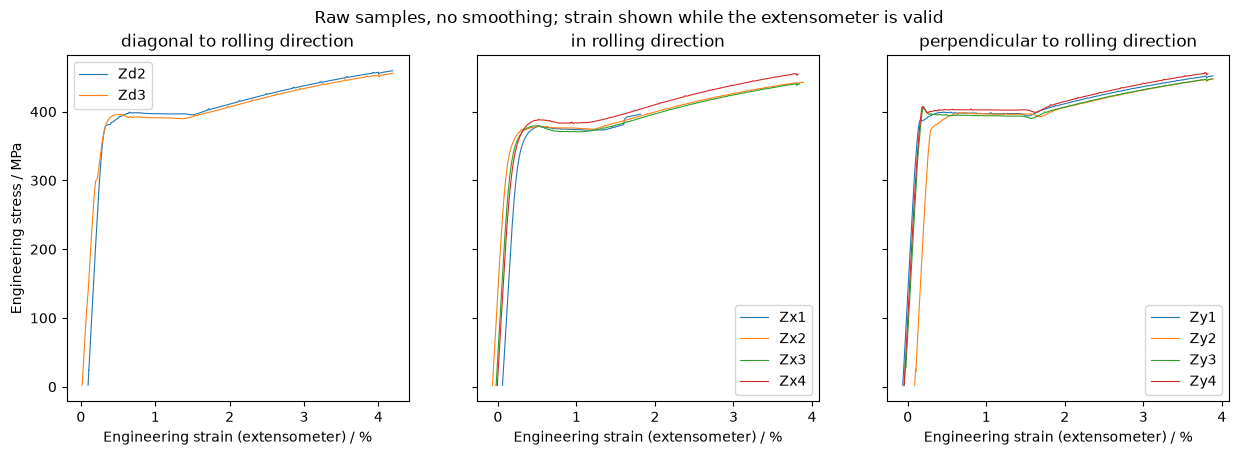

In [11]:
orientations = sorted(results["orientation"].unique())
fig, axes = plt.subplots(1, len(orientations), figsize=(5 * len(orientations), 4.5), sharey=True, squeeze=False)
for specimen_id, row in results.iterrows():
    specimen = acquisition.build_specimen_record(ontology_profile, source, specimen_id, curve_locator)
    raw = acquisition.download_curve(specimen)
    if raw.sha256 != row["curve_sha256"]:
        raise RuntimeError(f"The curve of {specimen_id} differs from the one analysed.")
    _, k_ext, _ = analysis.extensometer_validity(
        raw.strain, raw.crosshead_mm, specimen.l0_mm, row["a_percent"], specimen.rate_switch_strain
    )
    stress_mpa = analysis.engineering_stress(raw.force_n, specimen.s0_mm2)
    ax = axes[0, orientations.index(row["orientation"])]
    ax.plot(100 * raw.strain[:k_ext], stress_mpa[:k_ext], linewidth=0.8, label=specimen_id)
for ax, orientation in zip(axes[0], orientations):
    ax.set(title=orientation, xlabel="Engineering strain (extensometer) / %")
    ax.legend()
axes[0, 0].set_ylabel("Engineering stress / MPa")
fig.suptitle("Raw samples, no smoothing; strain shown while the extensometer is valid")
plt.show()

## 7. Switching the ontology to PMDco3/TTO

The same tests are also described with PMDco 3 and the Tensile Test Ontology in `S355_data_tto_pmdco3.ttl` of [materialdigital/tensile-test-ontology](https://github.com/materialdigital/tensile-test-ontology), pinned to commit `08a7aec`. Switching changes the profile ID to `pmdco3-tto` and the source to that graph.

That graph does not link the per-test curve files, so this switch also needs the optional third input. The profile declares an explicit **non-semantic curve locator**: a URL template for the curve CSVs in the same repository, at the same commit, and a declared map from CSV header names to curve roles and units. It is not knowledge from the graph. We pass it as a workflow input, so the run's knowledge graph records it.

The curve files there are expected to be byte-identical to the ones linked by the pmdco2 graphs; the comparison below checks this for every specimen through `curve_sha256`. Identical raw bytes and identical metadata should give identical analysis results; only the curve URLs differ.

This tests that the result does not depend on the ontology, not that it is right: Zy3's yield type and Zd3's E are reproduced exactly.

*Execution class: network-read (the pinned graph and the curve CSVs from GitHub). Skipped if `run_pmdco3_comparison` is `False`.*

In [12]:
if run_pmdco3_comparison:
    pmdco3_source = {"kind": "turtle", "locations": [pmdco3_tto.PINNED_GRAPH_URL]}
    pmdco3_locator = pmdco3_tto.CURVE_LOCATOR.as_dict()  # NON-SEMANTIC: not knowledge from the graph.
    tensile_pmdco3 = workflows.run_tensile_analysis("pmdco3-tto", pmdco3_source, pmdco3_locator)
    results_pmdco3 = tensile_pmdco3.results.set_index("specimen_id")

    compared = [column for column in results.columns if column != "curve_url"]
    left, right = results[compared].sort_index(), results_pmdco3[compared].sort_index()
    if not left.index.equals(right.index):
        raise RuntimeError("The two profiles describe different specimens.")
    identical = left.map(repr) == right.map(repr)  # Exact and NaN-aware, also inside the tuple columns.
    print("Same workflow recipe:", tensile.batch_workflow.recipe == tensile_pmdco3.batch_workflow.recipe)
    print("Identical results in every column except curve_url:", bool(identical.all().all()))
    differing = [column for column in compared if not identical[column].all()]
    print(f"Columns compared: {len(compared)}. Columns that differ:", ", ".join(differing) or "none")
    display(pd.DataFrame({"pmdco2 (from the graph)": results["curve_url"],
                          "pmdco3 (non-semantic locator)": results_pmdco3["curve_url"]}))

Same workflow recipe: True
Identical results in every column except curve_url: True
Columns compared: 37. Columns that differ: none


,pmdco2 (from the graph),pmdco3 (non-semantic locator)
specimen_id,,
Zd2,https://data.pmds-mpcdf-2.pyiron.com/Zd2.csv,https://raw.githubusercontent.com/materialdigital/tensile-test-ontology/08a7aec359f1072b823362bd67fbb93a88643e6f/tensile_test_data/primary_data/Zd2.csv
Zd3,https://data.pmds-mpcdf-2.pyiron.com/Zd3.csv,https://raw.githubusercontent.com/materialdigital/tensile-test-ontology/08a7aec359f1072b823362bd67fbb93a88643e6f/tensile_test_data/primary_data/Zd3.csv
Zx1,https://data.pmds-mpcdf-2.pyiron.com/Zx1.csv,https://raw.githubusercontent.com/materialdigital/tensile-test-ontology/08a7aec359f1072b823362bd67fbb93a88643e6f/tensile_test_data/primary_data/Zx1.csv
Zx2,https://data.pmds-mpcdf-2.pyiron.com/Zx2.csv,https://raw.githubusercontent.com/materialdigital/tensile-test-ontology/08a7aec359f1072b823362bd67fbb93a88643e6f/tensile_test_data/primary_data/Zx2.csv
Zx3,https://data.pmds-mpcdf-2.pyiron.com/Zx3.csv,https://raw.githubusercontent.com/materialdigital/tensile-test-ontology/08a7aec359f1072b823362bd67fbb93a88643e6f/tensile_test_data/primary_data/Zx3.csv
Zx4,https://data.pmds-mpcdf-2.pyiron.com/Zx4.csv,https://raw.githubusercontent.com/materialdigital/tensile-test-ontology/08a7aec359f1072b823362bd67fbb93a88643e6f/tensile_test_data/primary_data/Zx4.csv
Zy1,https://data.pmds-mpcdf-2.pyiron.com/Zy1.csv,https://raw.githubusercontent.com/materialdigital/tensile-test-ontology/08a7aec359f1072b823362bd67fbb93a88643e6f/tensile_test_data/primary_data/Zy1.csv
Zy2,https://data.pmds-mpcdf-2.pyiron.com/Zy2.csv,https://raw.githubusercontent.com/materialdigital/tensile-test-ontology/08a7aec359f1072b823362bd67fbb93a88643e6f/tensile_test_data/primary_data/Zy2.csv
Zy3,https://data.pmds-mpcdf-2.pyiron.com/Zy3.csv,https://raw.githubusercontent.com/materialdigital/tensile-test-ontology/08a7aec359f1072b823362bd67fbb93a88643e6f/tensile_test_data/primary_data/Zy3.csv


### Gaps found in the PMDco3/TTO data

Writing the `pmdco3-tto` profile showed where the graph's description of the data is incomplete or ambiguous:

- **No curve links.** Only the aggregate table `S355_data.csv` is linked via CSVW, not the per-test curves, hence the non-semantic locator above.
- **No orientation concept.** The rolling direction is a quality typed only as the generic `BFO_0000019` (quality); the profile finds it by structure.
- **Notes by label.** Lab notes and the process identifier are distinguished only by an instance label.
- **Shared classes.** L0 and the extensometer gauge length share a class, as do Fm and the load cell's force range; every quantity has to be constrained by its bearer.
- **Questionable terms.** `PMD_0020005`, labelled *porosity*, links the test piece to its material, and several TTO classes used by the data are deprecated in the same commit's source ontology.
- **Units and file format.** `unit:MegaPa` and `unit:GigaPa` are not QUDT IRIs and are mapped by declared aliases. Neither graph declares the CSV dialect (`;` delimiter, `,` decimal mark), which is a declared assumption in the package.

## 8. The workflow as a knowledge graph (semantikon)

semantikon describes a workflow with its own vocabulary: PMDco 3 and OBO terms for functions, ports and data, and QUDT for units. This is independent of the ontology that describes the tensile-test data. We export four graphs:

- the **recipes** of both stages: what will run;
- the **runs** of both stages: what ran, with the input values, results and provenance hashes.

Credentials never appear in them, because they are not workflow inputs. Array values appear only in shortened form, which is why each specimen also records its raw-curve SHA-256 and URL as plain strings.

Saved graphs use **N-Triples**, which keeps every value exactly. A Turtle preview is shown for reading only: rdflib 7.6.0 writes `xsd:double` values in Turtle with 7 significant digits.

*Execution class: read-only (local; files are written only to `kg_output_dir` or a temporary directory).*

In [13]:
graphs = {
    "exploration recipe": kg.recipe_knowledge_graph(tensile.exploration_node),
    "exploration run": kg.run_knowledge_graph(tensile.exploration_run),
    "batch recipe": kg.recipe_knowledge_graph(tensile.batch_workflow),
    "batch run": kg.run_knowledge_graph(tensile.batch_run),
}

if kg_output_dir is None:
    kg_tempdir = tempfile.TemporaryDirectory(prefix="tensile-kg-")
    output_dir = Path(kg_tempdir.name)
else:
    output_dir = Path(kg_output_dir).expanduser().resolve()
    # Compared in lower case, so a case variant on a case-insensitive file system is also refused.
    if Path(str(output_dir).casefold()).is_relative_to(str(demo_dir.parent.resolve()).casefold()):
        raise ValueError("Choose a kg_output_dir outside the repository.")
    output_dir.mkdir(parents=True, exist_ok=True)

graph_files = {name: output_dir / f"{name.replace(' ', '_')}.nt" for name in graphs}
existing_files = [path.name for path in graph_files.values() if path.exists()]
if existing_files:
    raise FileExistsError(f"kg_output_dir already holds {existing_files}; choose a new directory.")

saved = {}
for name, graph in graphs.items():
    path = kg.write_graph(graph, graph_files[name])
    saved[name] = {"file": path.name, "triples": len(graph), "triples read back": len(kg.read_graph(path))}
display(pd.DataFrame(saved).T)

,file,triples,triples read back
exploration recipe,exploration_recipe.nt,315,315
exploration run,exploration_run.nt,338,338
batch recipe,batch_recipe.nt,40148,40148
batch run,batch_run.nt,45305,45305


In [14]:
print(kg.TURTLE_PRECISION_NOTE, end="\n\n")
print("\n".join(kg.to_turtle(graphs["exploration recipe"]).splitlines()[:40]))

Turtle is for display only: rdflib 7.6.0 writes xsd:double literals with 7 significant digits (e.g. 400.26355612345 -> 4.002636e+02), so double values do not survive a Turtle round trip. Saved graphs use N-Triples, which is lossless.

@prefix bfo: <http://purl.obolibrary.org/obo/BFO_> .
@prefix iao: <http://purl.obolibrary.org/obo/IAO_> .
@prefix obi: <http://purl.obolibrary.org/obo/OBI_> .
@prefix owl: <http://www.w3.org/2002/07/owl#> .
@prefix pmdco: <https://w3id.org/pmd/co/PMD_> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix ro: <http://purl.obolibrary.org/obo/RO_> .
@prefix sns: <http://pyiron.org/ontology/> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

sns:7195063e5e1c8851937def90375e7774_exploration_workflow a sns:W7195063e_exploration_workflow ;
    rdfs:label "719506_exploration_workflow" ;
    bfo:0000051 sns:7195063e5e1c8851937def90375e7774_exploration_workflow-check_conformance_0,
        sns:7195063e5e1c8851937def90375e7774_exploration_workflow-i

### Example queries

Three SPARQL queries from the package run on the workflow graphs:

- **(a)** Which steps are ontology-aware and which are ontology-agnostic? The role follows from the Python module that the graph records for each step's function.
- **(b)** Which units and QUDT quantity kinds do the analysis outputs carry? No domain-ontology concept is needed for that.
- **(c)** Which inputs did the run use? The profile ID, the source and the specimen IDs, and for the PMDco3 run also the non-semantic curve locator.

*Execution class: read-only (local).*

In [15]:
roles = pd.concat(
    [kg.run_example_query(graphs[name], "step_roles") for name in ("exploration run", "batch run")]
)
display(roles.groupby("role")["function"].agg(lambda functions: ", ".join(sorted(set(functions)))).to_frame())

units = kg.run_example_query(graphs["batch run"], "analysis_output_units")
display(units.replace(r"^http://qudt\.org/vocab/(unit|quantitykind)/", "", regex=True))

display(kg.run_example_query(graphs["batch run"], "run_inputs"))
if run_pmdco3_comparison:
    display(kg.run_example_query(kg.run_knowledge_graph(tensile_pmdco3.batch_run), "run_inputs"))

,function
role,
ontology-agnostic: analysis,"assemble_curve_analysis, bootstrap_fit, check_time_order, compare_with_reported, count_dropped_samples, elongation_after_fracture, elongation_at_maximum_force, extensometer_validity, final_elastic_fit, maximum_force, proof_strength, reduction_of_area, s0_scatter, summarize_by_group, window_sensitivity, yield_analysis"
ontology-agnostic: contract adapter,"comparison_table, computed_properties, curve_channels, percent_value, results_table, specimen_geometry, specimen_summary, summary_quantities"
ontology-aware: acquisition,"fetch_curve, get_reported_properties, get_specimen_record"
ontology-aware: exploration,"check_conformance, list_specimens"
workflow composition,"exploration_workflow, specimen_workflow"
workflow plumbing (flowrep),TransformNto1.inputs_to_list


,function,output,unit,quantity_kind
0,bootstrap_fit,noise_mpa,MegaPA,Stress
1,elongation_at_maximum_force,ag_percent,PERCENT,Strain
2,elongation_at_maximum_force,agt_percent,PERCENT,Strain
3,extensometer_validity,extensometer_max_valid_strain,UNITLESS,Strain
4,final_elastic_fit,e_gpa,GigaPA,ModulusOfElasticity
5,final_elastic_fit,strain_origin,UNITLESS,Strain
6,maximum_force,fm_n,N,Force
7,maximum_force,rm_mpa,MegaPA,Stress
8,proof_strength,rp02_mpa,MegaPA,Stress
9,yield_analysis,reh_mpa,MegaPA,Stress


,input,value
0,curve_locator,None
1,profile_id,pmdco2-tto
2,source,"{'kind': 'ontodocker', 'datasets': ['pmdco2_tto_example_parallel', 'pmdco2_tto_example_perpendicular', 'pmdco2_tto_example_diagonal']}"
3,specimen_id_0,Zd2
4,specimen_id_1,Zd3
5,specimen_id_2,Zx1
6,specimen_id_3,Zx2
7,specimen_id_4,Zx3
8,specimen_id_5,Zx4
9,specimen_id_6,Zy1


,input,value
0,curve_locator,"{'url_template': 'https://raw.githubusercontent.com/materialdigital/tensile-test-ontology/08a7aec359f1072b823362bd67fbb93a88643e6f/tensile_test_data/primary_data/{specimen_id}.csv', 'columns': {'time': {'header': 'Time', 'unit': 's'}, 'crosshead': {'header': 'Crosshead separation', 'unit': 'mm'}, 'force': {'header': 'Load', 'unit': 'kN'}, 'strain': {'header': 'Extensometer elongation', 'unit': '%'}}}"
1,profile_id,pmdco3-tto
2,source,"{'kind': 'turtle', 'locations': ['https://raw.githubusercontent.com/materialdigital/tensile-test-ontology/08a7aec359f1072b823362bd67fbb93a88643e6f/tensile_test_data/S355_data_tto_pmdco3.ttl']}"
3,specimen_id_0,Zd2
4,specimen_id_1,Zd3
5,specimen_id_2,Zx1
6,specimen_id_3,Zx2
7,specimen_id_4,Zx3
8,specimen_id_5,Zx4
9,specimen_id_6,Zy1


### Validation

`semantikon.validate_values` checks each graph with OWL-RL reasoning and SHACL shapes, e.g. that connected ports have compatible units. For the batch graphs this takes some seconds.

*Execution class: read-only (local).*

In [16]:
for name, graph in graphs.items():
    conforms, report = kg.validate_knowledge_graph(graph)
    print(f"{name}: {'conforms' if conforms else 'does not conform'}")
    if not conforms:
        print(report[:2000])

exploration recipe: conforms
exploration run: conforms


batch recipe: conforms


batch run: conforms


## 9. Limitations and open points

- **ISO-inspired, not conformant.** All properties are method-defined, ISO 6892-1-inspired. The standard text was not available while the method was designed; nothing here claims conformity with ISO 6892-1 or its Annex G, or certifies the material.
- **Extensometer, Ag and Agt.** On all ten records the strain column ends at a pause of 16–25 s in the time column, during which the crosshead hardly moves and the force falls by 2.6–5.4 %. The last recorded strain is about 1.93 % on Zx1, 3.90–3.91 % on Zx2–Zx4 and Zy1–Zy4, and 4.20–4.21 % on Zd2 and Zd3. The lab notes record removal of the extensometer after 3.9 % strain only on Zx2, Zx3 and Zx4; removal on the other seven is our inference, not a statement of the graphs. The detected extensometer end lies up to one crosshead window (at most 0.11 percentage points of strain here) before the last recorded strain. The force maximum lies far beyond it on every specimen, so **Ag and Agt are NaN on all ten**, with the flag `extensometer_invalid`, and are not estimated from the crosshead. The flag `extensometer_ended_early` compares with A, so it is absent on Zx1 and Zy1, where A is missing, although their strain also ends early. ReL is also NaN, with the flag `rel:extensometer_invalid`, if the plateau is still running at the extensometer end, because its extent is then unknown; no specimen here is affected.
- **Test speed.** The graphs give a testing-rate transition point of 1.6 % strain on Zx1, 3.8 % on Zx2–Zx4 and Zy1–Zy4, and 4.0 % on Zd2 and Zd3. On Zx1 the crosshead then speeds up to about 0.5 mm/s, as the lab note says, and Fm is reached after about 110 s. On the other nine the crosshead runs at about 0.02 mm/s after that point and does not speed up, and Fm is reached after 740–810 s; the lab notes say this for Zx2–Zx4. The flag `extensometer:near_rate_switch` means that the extensometer end lies within 0.2 percentage points of the transition point; it is absent on Zx1 only because that distance is 0.22 points there. No ReH, ReL or Rp0.2 value carries a `near_rate_switch` flag.
- **E is not a material modulus.** It is the regression slope of the elastic part (mE-type), not Annex-G-conformant. The extensometer class is unknown, which alone allows slope errors of about 10 %.
- **Lab values are not ground truth.** The comparison shows consistency with the lab's software, not validation of either.
- **Uncertainty is partial.** Force and extensometer classes, calibration, Lu and Su, sampling resolution, noise bias and rate effects are not included.
- **Records whose stress never returns to ReH.** The evaluation ends such a record at the last sample above half of the highest force, which removes an abrupt final drop but not a gradual one. On a synthetic curve, necking to 80 % of Rm before fracture gives ReL 316 instead of 379 MPa, and Fm NaN. Every result from this case carries the flag `fm:no_return_to_reh`. The S355 tests are expected not to be affected, and section 6 names any specimen that is.
- **Yield type under noise.** A noisy plateau *without* an upper peak can be classified as discontinuous, which reports a spurious ReH. On a synthetic curve this happened in 44 % of 1000 seeds at 0.5 MPa noise. This is unlikely to matter on these tests: the lab reports a ReH for every one, and the nine ReH values found here lie within about 0.17 % of the lab's. The opposite failure does occur, as the next point shows.
- **Zy3: a real yield peak is missed.** The curve has a clear stress maximum of 407.6 MPa at 0.20 % strain, followed by a drop and a plateau, and the lab reports ReH 408 MPa, yet the method reports continuous yielding. At about 34 MPa the force falls by about 21 % within 0.07 s while the crosshead keeps moving. This lies inside the provisional fit window, so the noise level from that fit becomes 4.9 MPa, against 0.08–0.48 MPa on eight other specimens and 1.1 MPa on Zd3 (these values come from the analysis diagnostics and are not in the tables). The required drop becomes 24.4 MPa, more than the 17.5 MPa that occurs before the extensometer end, so the search runs on to the force maximum. That is why the flag `reh:extensometer_invalid` appears; the extensometer was working at the peak. ReH and ReL are NaN, and the ReH outcome `not_comparable` is neither agreement nor disagreement with the lab. The reported Rp0.2 (395.8 MPa) lies on the plateau after the peak, so it is a plateau stress, although the flag `in_yield_plateau` is missing. The nominal E window starts above the event, and Rm does not use strain; the low end of the E range (175 GPa) and `e_linearity_rel_diff` = +0.26 come from windows that include the event. We report the result as the approved method gives it, because changing the method after seeing this comparison would make a new agreement with the lab uninformative. The weakness is not specific to Zy3: Zy2 has a similar event at about 26 MPa, at the edge of its fit window, and Zd3 passes the yield test narrowly (drop 6.5 MPa, required 5.5 MPa).
- **ReL on a smoothly rising plateau.** The plateau level is a median, so the recovery falls mid-plateau. Without noise, ReL becomes the transient minimum with the flag `single_minimum`; with noise, it is about the plateau level minus the noise extreme. ReL is not compared with lab values.
- **Workflow structure.** The specimen fan-out is a programmatically assembled flat workflow, because semantikon cannot yet export workflows with loops ([pyiron/semantikon#541](https://github.com/pyiron/semantikon/issues/541)). Once that is fixed, a `for` loop can replace it.

Possible follow-ups:

- expose the analysis parameters as a workflow input, so that they are recorded in the run's knowledge graph;
- add a prominence criterion to the yield-type rule, a rising-plateau reference case with a declared ReL, and a better end-of-record rule for records whose stress never returns to ReH;
- a noise estimate for the yield rule that does not react to low-load events or curvature, and a declared flag for an elastic segment that is not straight;
- report upstream: the Turtle precision of `xsd:double` in rdflib, blank nodes named after IRIs in semantikon, and the PMDco3/TTO data gaps listed in section 7;
- link the per-test curves in the PMDco3/TTO graph, so that the non-semantic locator is no longer needed;
- publish the results and workflow graphs, which needs a separate decision.